In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Clean_popular_cities_weather.csv")

print(df.head())
print(df.shape)
print(df.info())

               Date  Average_Temperature  Minimum_Temperature  \
0  01-01-2020 00:00                 24.9                 19.2   
1  01-02-2020 00:00                 27.3                 21.0   
2  01-03-2020 00:00                 27.7                 22.6   
3  01-04-2020 00:00                 30.2                 26.4   
4  01-05-2020 00:00                 31.1                 28.6   

   Maximum_Temperature  Precipitation  Atmospheric_Pressure  \
0                 29.9            0.0                1013.4   
1                 32.6            0.0                1012.7   
2                 31.9            0.0                1011.2   
3                 33.9            0.0                1009.6   
4                 34.0            0.0                1007.3   

   Sunshine_Duration    city  
0            13800.0  Mumbai  
1            11220.0  Mumbai  
2            12900.0  Mumbai  
3            14220.0  Mumbai  
4            15960.0  Mumbai  
(7056, 8)
<class 'pandas.core.frame.DataFram

In [2]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
print(df.describe())

Missing Values:
Date                       0
Average_Temperature      539
Minimum_Temperature      604
Maximum_Temperature      625
Precipitation            930
Atmospheric_Pressure     622
Sunshine_Duration       4651
city                       0
dtype: int64

Duplicate Rows:
144

Statistical Summary:
       Average_Temperature  Minimum_Temperature  Maximum_Temperature  \
count          6517.000000          6452.000000          6431.000000   
mean             25.896179            20.843971            31.630944   
std               5.220012             5.724433             5.035931   
min               0.600000            -4.500000             5.700000   
25%              23.300000            17.200000            29.300000   
50%              27.100000            22.600000            32.000000   
75%              29.500000            25.300000            34.700000   
max              36.600000            31.000000            44.000000   

       Precipitation  Atmospheric_Pressure  Sun

In [3]:
# Convert dates using the correct format
df["Date"] = pd.to_datetime(
    df["Date"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

# Standardize city names
df["city"] = df["city"].str.strip().str.title()

# Remove exact duplicate records
df = df.drop_duplicates()

# Sort records
df = df.sort_values(["city", "Date"])

print(df.shape)

(6912, 8)


In [4]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df)) * 100
})

print(missing)

                      Missing_Count  Missing_Percentage
Date                              0            0.000000
Average_Temperature             526            7.609954
Minimum_Temperature             591            8.550347
Maximum_Temperature             612            8.854167
Precipitation                   913           13.208912
Atmospheric_Pressure            608            8.796296
Sunshine_Duration              4507           65.205440
city                              0            0.000000


In [6]:
city_missing = df.groupby("city").apply(
    lambda x: x.isnull().sum()
)

print(city_missing)

               Date  Average_Temperature  Minimum_Temperature  \
city                                                            
Agra              0                    0                    0   
Ahmedabad         0                    0                    0   
Ajmer             0                   13                   13   
Akola             0                    0                    0   
Aligarh           0                    0                    0   
...             ...                  ...                  ...   
Varanasi          0                   12                   13   
Vasai-Virar       0                    0                    0   
Vijayawada        0                    0                    0   
Visakhapatnam     0                    0                    0   
Warangal          0                   13                   13   

               Maximum_Temperature  Precipitation  Atmospheric_Pressure  \
city                                                                      
Agra

/tmp/ipykernel_1429/740696604.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  city_missing = df.groupby("city").apply(


In [7]:
duplicates = df.duplicated(
    subset=["city", "Date"],
    keep=False
)

print(df[duplicates].sort_values(["city", "Date"]))

Empty DataFrame
Columns: [Date, Average_Temperature, Minimum_Temperature, Maximum_Temperature, Precipitation, Atmospheric_Pressure, Sunshine_Duration, city]
Index: []


In [8]:
# Columns suitable for interpolation
interpolate_cols = [
    "Average_Temperature",
    "Minimum_Temperature",
    "Maximum_Temperature",
    "Atmospheric_Pressure"
]

# Sort data chronologically
df = df.sort_values(["city", "Date"])

# Interpolate within individual cities
for col in interpolate_cols:
    df[col] = df.groupby("city")[col].transform(
        lambda x: x.interpolate(
            method="linear",
            limit_area="inside"
        )
    )

In [9]:
sunshine_analysis = df.groupby("city").agg(
    Total_Records=("Sunshine_Duration", "count"),
    Missing_Records=("Sunshine_Duration",
                     lambda x: x.isnull().sum())
)

sunshine_analysis["Missing_Percentage"] = (
    sunshine_analysis["Missing_Records"] /
    (sunshine_analysis["Total_Records"] +
     sunshine_analysis["Missing_Records"])
) * 100

print(
    sunshine_analysis.sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

            Total_Records  Missing_Records  Missing_Percentage
city                                                          
Agra                    0               72               100.0
Ajmer                   0               72               100.0
Akola                   0               72               100.0
Allahabad               0               72               100.0
Amravati                0               72               100.0
...                   ...              ...                 ...
Guntur                 72                0                 0.0
Maheshtala             72                0                 0.0
Kolkata                72                0                 0.0
Pune                   72                0                 0.0
Vijayawada             72                0                 0.0

[96 rows x 3 columns]


In [10]:
invalid_temp = df[
    (df["Minimum_Temperature"] >
     df["Average_Temperature"]) |
    (df["Average_Temperature"] >
     df["Maximum_Temperature"])
]

print("Inconsistent temperature records:",
      len(invalid_temp))

print(invalid_temp.head())

Inconsistent temperature records: 0
Empty DataFrame
Columns: [Date, Average_Temperature, Minimum_Temperature, Maximum_Temperature, Precipitation, Atmospheric_Pressure, Sunshine_Duration, city]
Index: []


In [11]:
print("Remaining Missing Values:")
print(df.isnull().sum())

print("\nRemaining Missing Percentage:")
print((df.isnull().sum() / len(df)) * 100)

print("\nDataset Shape:")
print(df.shape)

Remaining Missing Values:
Date                       0
Average_Temperature      421
Minimum_Temperature      468
Maximum_Temperature      475
Precipitation            913
Atmospheric_Pressure     461
Sunshine_Duration       4507
city                       0
dtype: int64

Remaining Missing Percentage:
Date                     0.000000
Average_Temperature      6.090856
Minimum_Temperature      6.770833
Maximum_Temperature      6.872106
Precipitation           13.208912
Atmospheric_Pressure     6.669560
Sunshine_Duration       65.205440
city                     0.000000
dtype: float64

Dataset Shape:
(6912, 8)


In [12]:
print("Negative Precipitation:",
      (df["Precipitation"] < 0).sum())

print("Negative Sunshine Duration:",
      (df["Sunshine_Duration"] < 0).sum())

Negative Precipitation: 0
Negative Sunshine Duration: 0


In [13]:
print(df["Precipitation"].describe())

print("Zero rainfall:",
      (df["Precipitation"] == 0).sum())

print("Missing rainfall:",
      df["Precipitation"].isnull().sum())

count    5999.000000
mean      118.260393
std       181.478213
min         0.000000
25%         3.000000
50%        45.000000
75%       170.300000
max      1768.900000
Name: Precipitation, dtype: float64
Zero rainfall: 863
Missing rainfall: 913


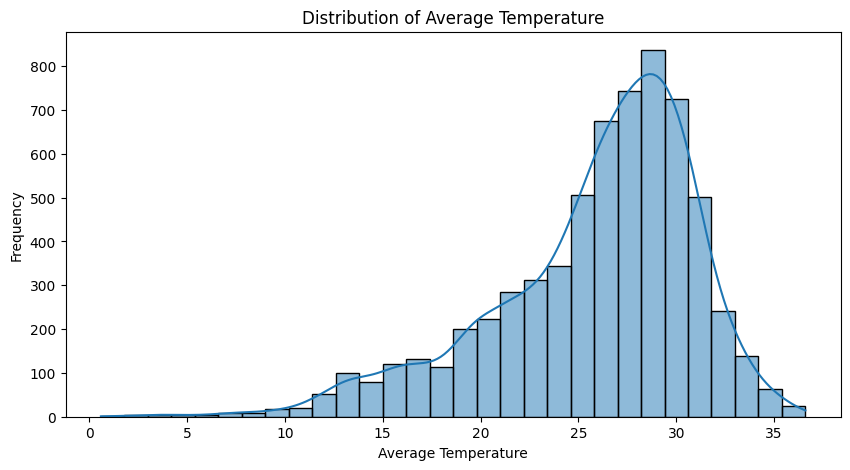

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Average_Temperature",
    bins=30,
    kde=True
)

plt.title("Distribution of Average Temperature")
plt.xlabel("Average Temperature")
plt.ylabel("Frequency")

plt.show()

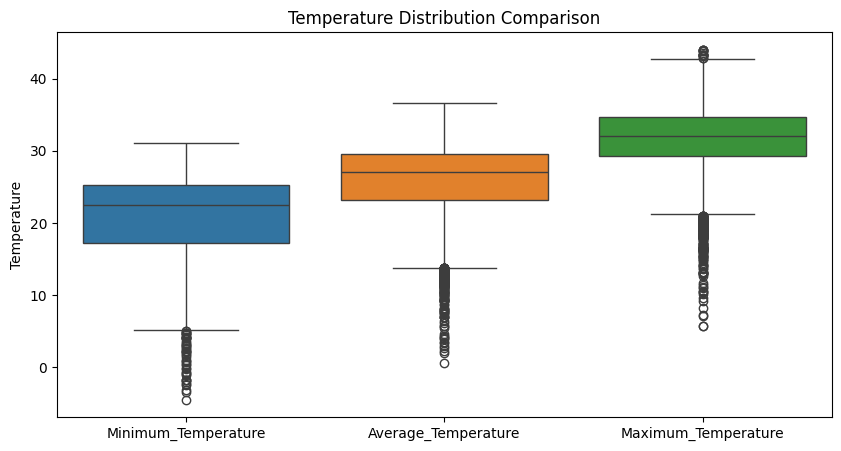

In [15]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df[
        [
            "Minimum_Temperature",
            "Average_Temperature",
            "Maximum_Temperature"
        ]
    ]
)

plt.title("Temperature Distribution Comparison")
plt.ylabel("Temperature")

plt.show()

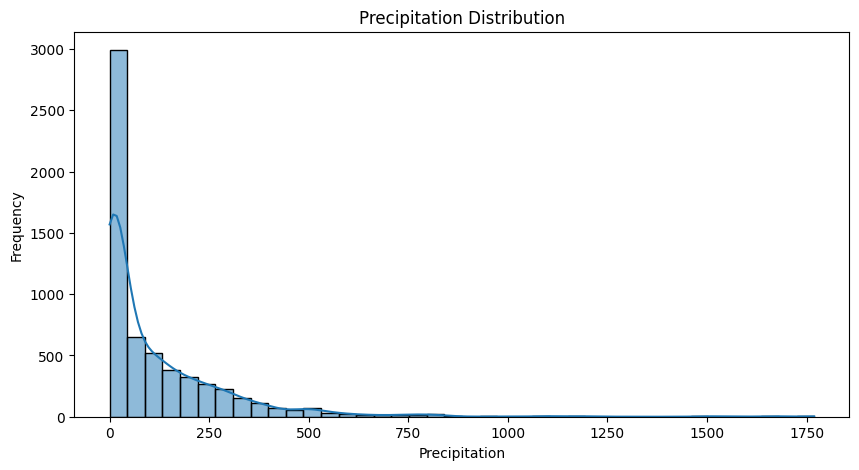

In [16]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Precipitation",
    bins=40,
    kde=True
)

plt.title("Precipitation Distribution")
plt.xlabel("Precipitation")
plt.ylabel("Frequency")

plt.show()

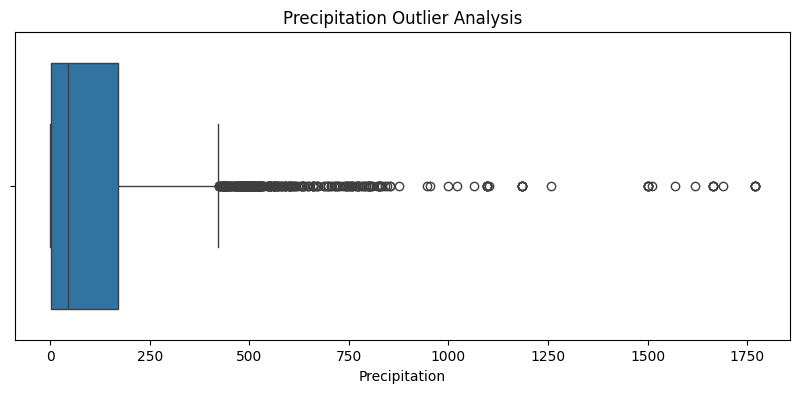

In [17]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["Precipitation"])

plt.title("Precipitation Outlier Analysis")
plt.show()

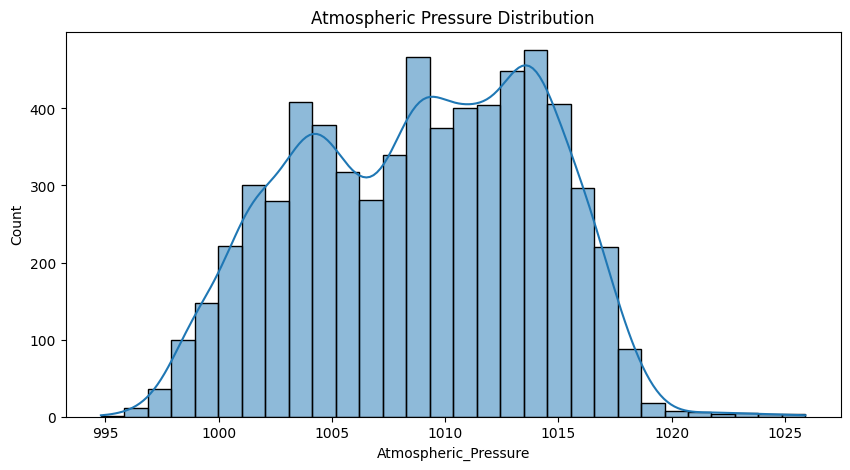

In [18]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Atmospheric_Pressure",
    bins=30,
    kde=True
)

plt.title("Atmospheric Pressure Distribution")
plt.show()

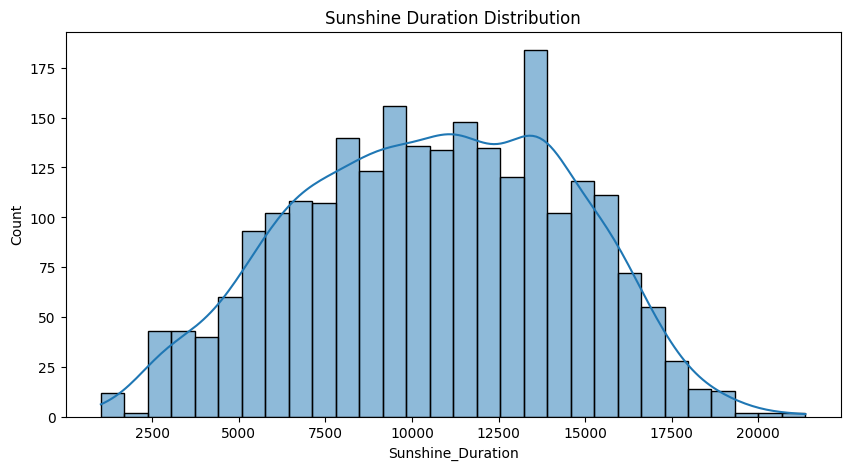

In [19]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Sunshine_Duration",
    bins=30,
    kde=True
)

plt.title("Sunshine Duration Distribution")
plt.show()

In [20]:
for col in [
    "Average_Temperature",
    "Precipitation",
    "Atmospheric_Pressure",
    "Sunshine_Duration"
]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) | (df[col] > upper)
    ]

    print(col, "Outliers:", len(outliers))

Average_Temperature Outliers: 223
Precipitation Outliers: 332
Atmospheric_Pressure Outliers: 0
Sunshine_Duration Outliers: 0


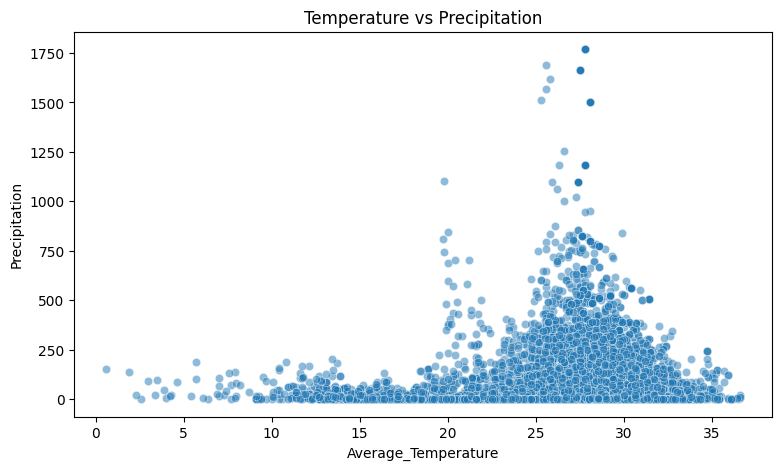

In [21]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Average_Temperature",
    y="Precipitation",
    alpha=0.5
)

plt.title("Temperature vs Precipitation")
plt.show()

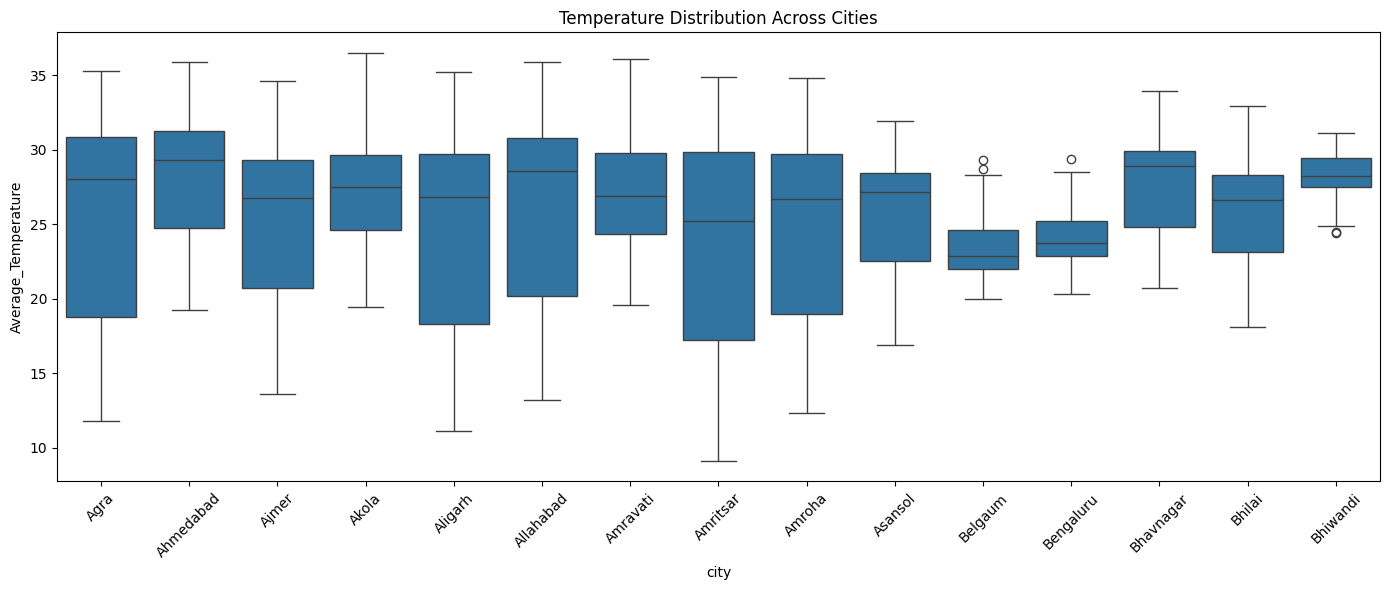

In [22]:
top_cities = df["city"].value_counts().head(15).index

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df[df["city"].isin(top_cities)],
    x="city",
    y="Average_Temperature"
)

plt.xticks(rotation=45)
plt.title("Temperature Distribution Across Cities")
plt.tight_layout()
plt.show()

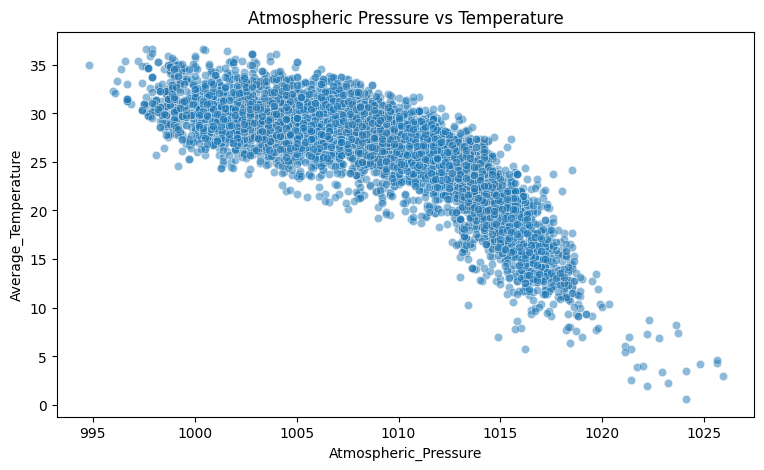

In [23]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Atmospheric_Pressure",
    y="Average_Temperature",
    alpha=0.5
)

plt.title("Atmospheric Pressure vs Temperature")
plt.show()

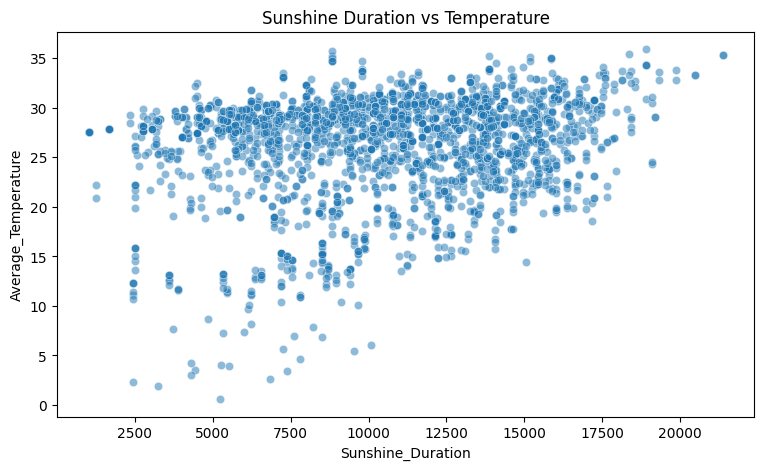

In [24]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Sunshine_Duration",
    y="Average_Temperature",
    alpha=0.5
)

plt.title("Sunshine Duration vs Temperature")
plt.show()

In [25]:
correlation = df.select_dtypes(
    include="number"
).corr()

print(correlation.round(3))

                      Average_Temperature  Minimum_Temperature  \
Average_Temperature                 1.000                0.956   
Minimum_Temperature                 0.956                1.000   
Maximum_Temperature                 0.945                0.821   
Precipitation                       0.188                0.350   
Atmospheric_Pressure               -0.794               -0.836   
Sunshine_Duration                   0.198                0.004   

                      Maximum_Temperature  Precipitation  \
Average_Temperature                 0.945          0.188   
Minimum_Temperature                 0.821          0.350   
Maximum_Temperature                 1.000         -0.021   
Precipitation                      -0.021          1.000   
Atmospheric_Pressure               -0.673         -0.435   
Sunshine_Duration                   0.402         -0.543   

                      Atmospheric_Pressure  Sunshine_Duration  
Average_Temperature                 -0.794          

In [26]:
print(
    df.groupby("city")["Average_Temperature"]
      .mean()
      .sort_values(ascending=False)
      .head(10)
)

print(
    df.groupby("city")["Average_Temperature"]
      .mean()
      .sort_values()
      .head(10)
)

city
Tiruchirappalli       29.225000
Kozhikode             29.213889
Nellore               28.665000
Vijayawada            28.533333
Madurai               28.515278
Thiruvananthapuram    28.461111
Bhiwandi              28.341667
Kalyan-Dombivli       28.341667
Mumbai                28.341667
Vasai-Virar           28.341667
Name: Average_Temperature, dtype: float64
city
Srinagar      14.550000
Shimla        16.080833
Chandigarh    19.404167
Tiruppur      20.497500
Saharanpur    21.666154
Dehradun      21.699231
Jammu         22.340278
Belgaum       23.552778
Jalandhar     23.562500
Amritsar      23.590278
Name: Average_Temperature, dtype: float64


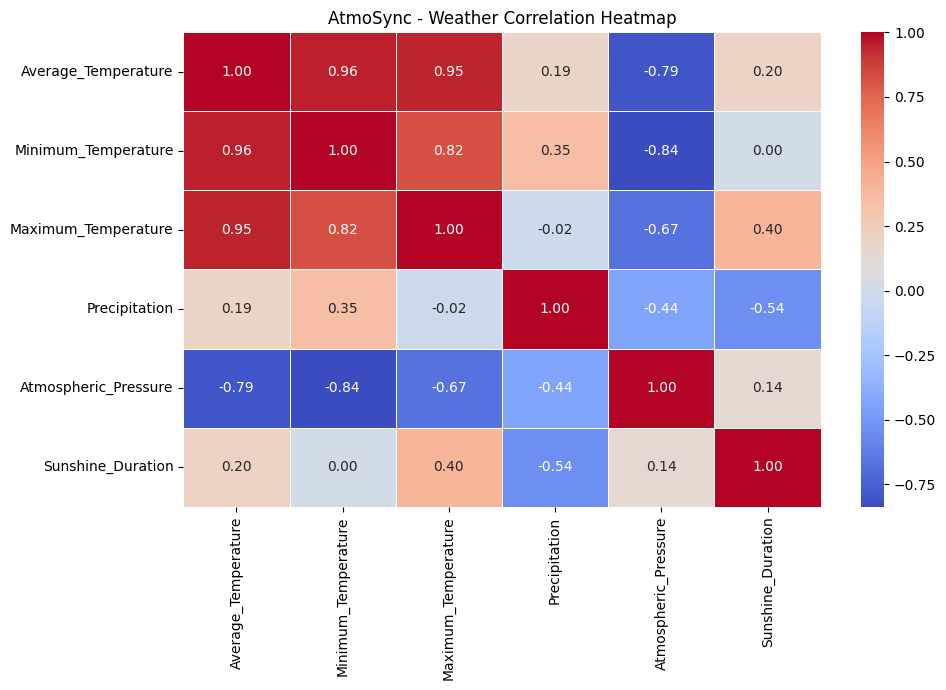

In [27]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("AtmoSync - Weather Correlation Heatmap")
plt.tight_layout()
plt.show()

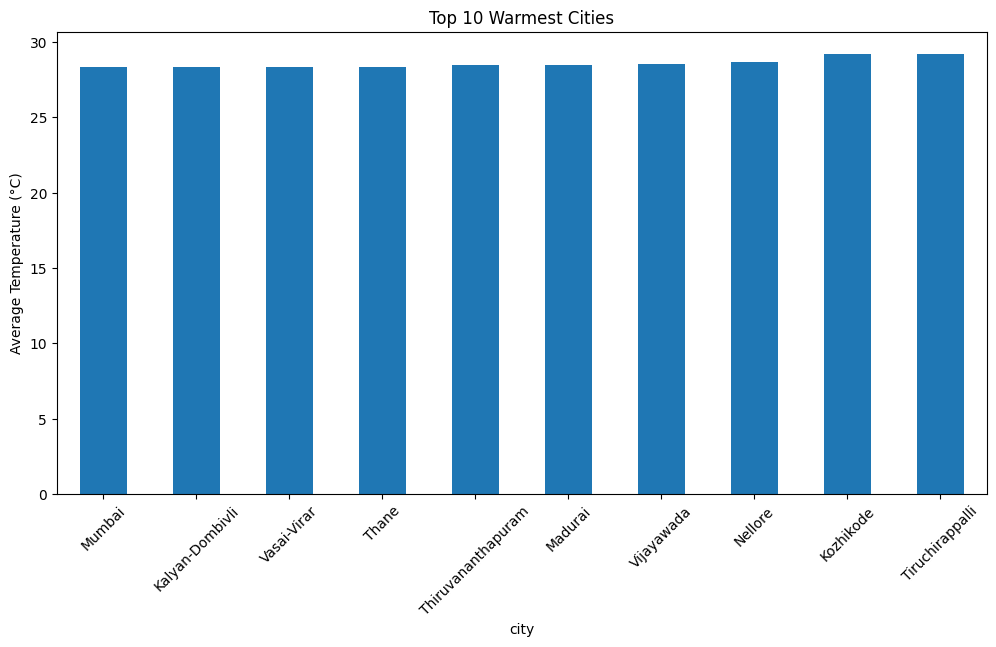

In [28]:
city_temp = df.groupby("city")[
    "Average_Temperature"
].mean().sort_values()

plt.figure(figsize=(12, 6))

city_temp.tail(10).plot(
    kind="bar",
    title="Top 10 Warmest Cities"
)

plt.ylabel("Average Temperature (°C)")
plt.xticks(rotation=45)
plt.show()

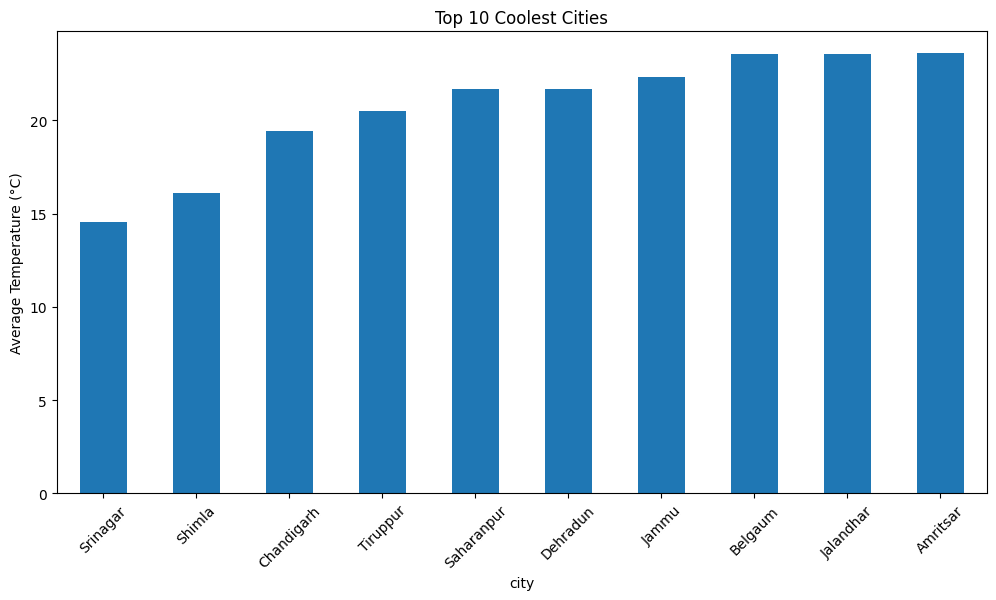

In [29]:
plt.figure(figsize=(12, 6))

city_temp.head(10).plot(
    kind="bar",
    title="Top 10 Coolest Cities"
)

plt.ylabel("Average Temperature (°C)")
plt.xticks(rotation=45)
plt.show()

In [30]:
city_records = df.groupby("city").agg(
    Total_Records=("Date", "count"),
    Available_Temperature=(
        "Average_Temperature", "count"
    ),
    Average_Temperature=(
        "Average_Temperature", "mean"
    )
)

print(
    city_records.sort_values(
        "Average_Temperature",
        ascending=False
    ).head(10).round(2)
)

                    Total_Records  Available_Temperature  Average_Temperature
city                                                                         
Tiruchirappalli                72                     72                29.22
Kozhikode                      72                     72                29.21
Nellore                        72                     60                28.67
Vijayawada                     72                     72                28.53
Madurai                        72                     72                28.52
Thiruvananthapuram             72                     72                28.46
Bhiwandi                       72                     72                28.34
Kalyan-Dombivli                72                     72                28.34
Mumbai                         72                     72                28.34
Vasai-Virar                    72                     72                28.34


In [31]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

print(missing_report)

                      Missing_Count  Missing_Percentage
Date                              0                0.00
Average_Temperature             421                6.09
Minimum_Temperature             468                6.77
Maximum_Temperature             475                6.87
Precipitation                   913               13.21
Atmospheric_Pressure            461                6.67
Sunshine_Duration              4507               65.21
city                              0                0.00


In [32]:
print("Dataset Shape:", df.shape)

print("\nDuplicate Rows:", df.duplicated().sum())

print("Duplicate City-Date Records:",
      df.duplicated(subset=["city", "Date"]).sum())

print("Invalid Dates:", df["Date"].isna().sum())

print("Invalid Temperature Records:",
      len(df[
          (df["Minimum_Temperature"] > df["Average_Temperature"]) |
          (df["Average_Temperature"] > df["Maximum_Temperature"])
      ]))

print("\nDate Range:")
print("Start:", df["Date"].min())
print("End:", df["Date"].max())

print("\nUnique Cities:", df["city"].nunique())




Dataset Shape: (6912, 8)

Duplicate Rows: 0
Duplicate City-Date Records: 0
Invalid Dates: 0
Invalid Temperature Records: 0

Date Range:
Start: 2020-01-01 00:00:00
End: 2025-12-01 00:00:00

Unique Cities: 96


In [33]:
print(df.describe().round(2))

                      Date  Average_Temperature  Minimum_Temperature  \
count                 6912              6491.00              6444.00   
mean   2022-12-16 06:40:00                25.83                20.81   
min    2020-01-01 00:00:00                 0.60                -4.50   
25%    2021-06-23 12:00:00                23.20                17.20   
50%    2022-12-16 12:00:00                27.00                22.50   
75%    2024-06-08 12:00:00                29.50                25.30   
max    2025-12-01 00:00:00                36.60                31.00   
std                    NaN                 5.22                 5.72   

       Maximum_Temperature  Precipitation  Atmospheric_Pressure  \
count              6437.00        5999.00               6451.00   
mean                 31.59         118.26               1008.85   
min                   5.70           0.00                994.80   
25%                  29.20           3.00               1004.50   
50%             

In [34]:
city_summary = df.groupby("city").agg(
    Average_Temperature=("Average_Temperature", "mean"),
    Average_Precipitation=("Precipitation", "mean"),
    Average_Pressure=("Atmospheric_Pressure", "mean"),
    Temperature_Std=("Average_Temperature", "std"),
    Records=("Date", "count")
)

print(city_summary.round(2).head(10))

           Average_Temperature  Average_Precipitation  Average_Pressure  \
city                                                                      
Agra                     25.18                  68.01           1008.11   
Ahmedabad                28.25                  80.11           1008.22   
Ajmer                    25.12                  77.93           1008.78   
Akola                    27.50                  86.48           1007.94   
Aligarh                  24.55                  73.55           1008.31   
Allahabad                25.95                  88.57           1007.58   
Amravati                 27.14                  94.40           1008.34   
Amritsar                 23.59                  70.70           1008.28   
Amroha                   24.56                  83.14           1008.34   
Asansol                  25.78                 121.95           1008.39   

           Temperature_Std  Records  
city                                 
Agra                  7

In [35]:
print(df.groupby("city").size().value_counts().sort_index())

72    96
Name: count, dtype: int64


In [36]:
df.to_csv("AtmoSync_Cleaned_Dataset.csv", index=False)
print("Export completed successfully!")

Export completed successfully!
